In [3]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.ticker import MaxNLocator

# repository root, whether the notebook runs from notebooks/ or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src.data import get_loaders
from src.models import build_model
from src.train import evaluate

FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
pdf = PdfPages(FIG_DIR / "d1_classifiers.pdf")

experiments = {               # label shown in plots -> output folder
    "MLP": ROOT / "outputs" / "MLP",
    "CNN": ROOT / "outputs" / "CNN",
}

def seed_dirs(exp_dir):
    dirs = sorted(Path(exp_dir).glob("seed_*"))
    if not dirs:
        raise FileNotFoundError(f"no seed_* folders in {Path(exp_dir).resolve()}")
    return dirs


def load_histories(exp_dir):
    return [json.load(open(d / "history.json")) for d in seed_dirs(exp_dir)]

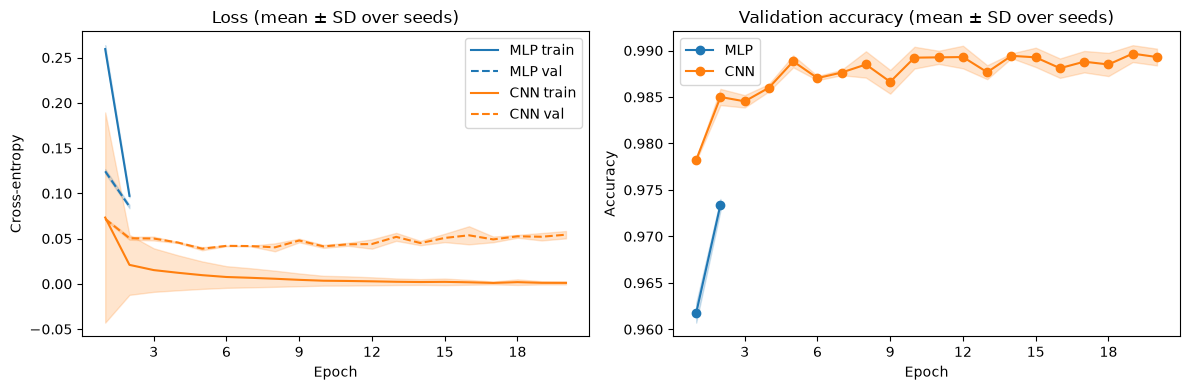

In [4]:
from matplotlib.ticker import MaxNLocator

def mean_sd(histories, key):
    values = np.array([h[key] for h in histories])      # (n_seeds, n_epochs)
    return values.mean(axis=0), values.std(axis=0, ddof=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, exp_dir in experiments.items():
    hs = load_histories(exp_dir)
    epochs = np.arange(1, len(hs[0]["train_loss"]) + 1)

    color = None
    for key, style, name in [("train_loss", "-", "train"), ("val_loss", "--", "val")]:
        m, s = mean_sd(hs, key)
        line, = axes[0].plot(epochs, m, style, color=color, label=f"{label} {name}")
        color = line.get_color()                         # reuse for this model's other curves
        axes[0].fill_between(epochs, m - s, m + s, color=color, alpha=0.2)

    m, s = mean_sd(hs, "val_acc")
    axes[1].plot(epochs, m, marker="o", color=color, label=label)
    axes[1].fill_between(epochs, m - s, m + s, color=color, alpha=0.2)

for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()

axes[0].set(title="Loss (mean ± SD over seeds)", xlabel="Epoch", ylabel="Cross-entropy")
axes[1].set(title="Validation accuracy (mean ± SD over seeds)", xlabel="Epoch", ylabel="Accuracy")
plt.tight_layout()
pdf.savefig(fig, bbox_inches="tight")
plt.show()

In [5]:
test_results = {}
for label, exp_dir in experiments.items():
    accs = []
    for d in seed_dirs(exp_dir):
        cfg = yaml.safe_load(open(d / "config.yaml"))
        _, _, test_loader = get_loaders(**cfg["data"])
        model = build_model(cfg["model"])
        model.load_state_dict(torch.load(d / "model.pt"))
        metrics = evaluate(model, test_loader)
        json.dump(metrics, open(d / "test_metrics.json", "w"))
        accs.append(metrics["val_acc"])          # key name comes from model.metrics
    test_results[label] = (np.mean(accs), np.std(accs, ddof=1), len(accs))

for label, (m, s, n) in test_results.items():
    print(f"{label:5s} test accuracy: {m:.2%} ± {s:.2%}  (n={n})")

MLP   test accuracy: 97.34% ± 0.12%  (n=3)
CNN   test accuracy: 98.97% ± 0.05%  (n=3)


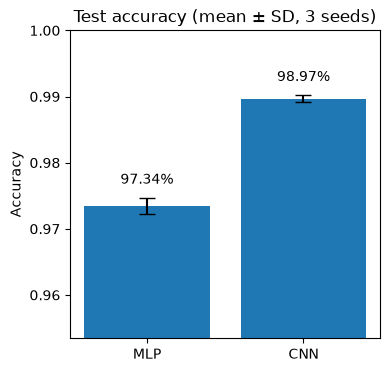

In [6]:
labels = list(test_results)
means = [test_results[l][0] for l in labels]
sds = [test_results[l][1] for l in labels]

fig, ax = plt.subplots(figsize=(4, 4))
bars = ax.bar(labels, means, yerr=sds, capsize=6)
ax.bar_label(bars, labels=[f"{m:.2%}" for m in means], padding=8)
ax.set(title="Test accuracy (mean ± SD, 3 seeds)", ylabel="Accuracy",
       ylim=(min(means) - 0.02, 1.0))
pdf.savefig(fig, bbox_inches="tight")
pdf.close()
plt.show()